# 02 · Preprocessing, model training, tuning and evaluation
Plan
1. Temporal split — train ≤ 2015, test 2016–2025 (unseen future seasons, includes the 2016/17 drought and the 2021/22 fertilizer ban).
2. Expanding-window cross-validation inside the training period for hyperparameter tuning.
3. Eight model families tuned with `RandomizedSearchCV` — no default hyperparameters.
4. Choose the model on **CV RMSE**, then report its **test** performance once.
5. Re-fit the chosen model on all seasons and save it for the app.

In [1]:
import sys, warnings, json
sys.path.insert(0, "..")
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from src import config as C
from src.features import TARGET, feature_list
from src.modeling import temporal_split, expanding_window_cv, make_preprocessor, model_zoo, shortfall_metrics, naive_baseline
from src import train as T

df = T.load_table()
features = feature_list(df)
train, test = temporal_split(df)
sns.set_theme(style="whitegrid"); FIG = C.FIGURES
print(f"train {train.shape}, test {test.shape}, features {len(features)}")

train (1784, 28), test (465, 28), features 23


## 1. Why a temporal split and expanding-window CV
A random 80/20 split would put 2020 seasons in training while predicting 2018 — information from the future (train–test contamination, Lecture 7). Each CV fold below trains only on seasons *before* its validation block.

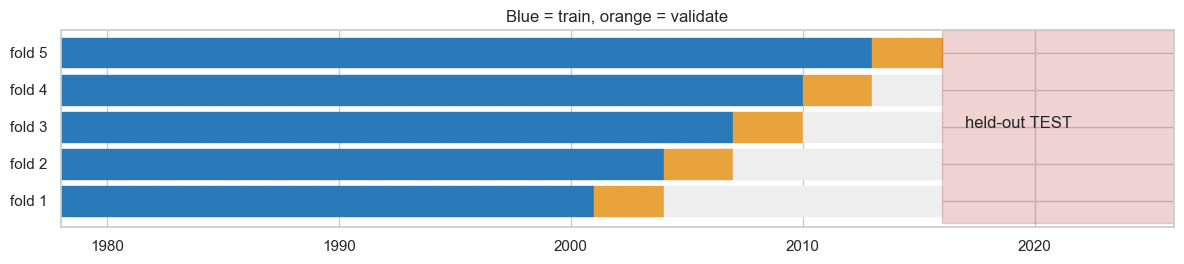

In [2]:
folds = expanding_window_cv(train)
fig, ax = plt.subplots(figsize=(12, 2.8))
years = np.arange(train.season_year.min(), C.TRAIN_END + 1)
for i, (tr, va) in enumerate(folds):
    tr_y, va_y = set(train.season_year.iloc[tr]), set(train.season_year.iloc[va])
    for y in years:
        ax.add_patch(plt.Rectangle((y, i), 1, .8, color="#2a7ab9" if y in tr_y else "#e8a33d" if y in va_y else "#eee"))
ax.add_patch(plt.Rectangle((C.TRAIN_END + 1, -0.2), df.season_year.max() - C.TRAIN_END, len(folds) + .2, color="#c0504d", alpha=.25))
ax.text(C.TRAIN_END + 2, len(folds) / 2, "held-out TEST", va="center")
ax.set_xlim(years[0], df.season_year.max() + 1); ax.set_ylim(-.3, len(folds)); ax.set_yticks(np.arange(len(folds)) + .4)
ax.set_yticklabels([f"fold {i+1}" for i in range(len(folds))]); ax.set_title("Blue = train, orange = validate")
plt.tight_layout(); plt.savefig(FIG / "cv_scheme.png", dpi=150); plt.show()

## 2. Preprocessing pipeline
* Numeric: median imputation **+ missing-indicator** → `StandardScaler` (scaling only for distance/margin based models: Ridge, KNN, SVR).
* Categorical (`district`, `season`): one-hot encoded.
* Everything is inside a `Pipeline`, so imputation and scaling are fitted on each CV training fold only (no preprocessing leakage).
* **Excluded on purpose:** harvested extent and production — only known after harvest (target leakage).

In [3]:
pre = make_preprocessor(features)
Xt = pre.fit_transform(train[features])
print("transformed shape:", Xt.shape)
Xt.iloc[:3, :12]

transformed shape: (1784, 65)


,season_year,fertilizer_crisis,prev_yield_same,prev_yield_any,yield_mean3_same,sown_ha,sown_change_pct,rain_total,rain_establish,rain_late,rain_days,rain_max5d
0,-1.730677,0.0,-0.011041,-0.015205,-0.023553,1.502250,-0.103816,-0.058099,-0.074126,-0.25744,-0.064671,-0.173647
1,-1.730677,0.0,-0.011041,-0.015205,-0.023553,3.296969,-0.103816,-0.058099,-0.074126,-0.25744,-0.064671,-0.173647
2,-1.730677,0.0,-0.011041,-0.015205,-0.023553,-0.100229,-0.103816,-0.058099,-0.074126,-0.25744,-0.064671,-0.173647


## 3. Models and hyperparameter search spaces
Every model is tuned with `RandomizedSearchCV` (sampling `N_ITER` combinations, scored by RMSE across the 5 time folds).

`uniform(loc, scale)` samples from [loc, loc + scale]; `loguniform(a, b)` samples evenly on a log scale between a and b (good for learning rate, C, α).

In [4]:
for name, (est, space) in model_zoo(features).items():
    print(f"{name}:")
    for k, v in space.items():
        print(f"    {k.split('__')[-1]:20s} {getattr(v, 'dist', None) and (v.dist.name, v.args) or v}")

Ridge (baseline):
    alpha                ('loguniform', (0.001, 1000.0))
KNN:
    n_neighbors          ('randint', (3, 40))
    weights              ['uniform', 'distance']
SVR (RBF):
    C                    ('loguniform', (0.1, 100))
    gamma                ['scale', 0.001, 0.003, 0.01, 0.03]
    epsilon              ('uniform', (0.02, 0.3))
Decision Tree:
    max_depth            ('randint', (3, 16))
    min_samples_leaf     ('randint', (5, 60))
    ccp_alpha            ('loguniform', (0.1, 10000.0))
Random Forest:
    n_estimators         ('randint', (200, 700))
    max_depth            [None, 8, 12, 16, 24]
    max_features         ['sqrt', 0.33, 0.5, 0.8]
    min_samples_leaf     ('randint', (1, 12))
Gradient Boosting:
    n_estimators         ('randint', (200, 800))
    learning_rate        ('loguniform', (0.01, 0.2))
    max_depth            ('randint', (2, 6))
    subsample            ('uniform', (0.6, 0.4))
    min_samples_leaf     ('randint', (3, 30))
XGBoost:
    n_estim

| Model | Why it is in the comparison |
|---|---|
| Ridge | Linear baseline with L2 regularisation (Lecture 3) — tests whether non-linearity is needed |
| KNN | Similarity-based: "seasons like this one had yields like…" |
| SVR (RBF) | Kernel method (Lecture 4); C and γ trade margin vs fit |
| Decision Tree | Interpretable single tree, cost-complexity pruning (Lecture 5) |
| Random Forest | Bagging + random feature subsets (Lecture 6) — variance reduction |
| Gradient Boosting / XGBoost / LightGBM | Sequential residual fitting (Lecture 7) — bias reduction; XGB/LGBM add L1/L2 regularisation |


In [5]:
N_ITER = 30      # random-search draws per model (x 5 folds x 9 models)
out = T.run(n_iter=N_ITER)
fitted, cv_table, test_table, best_name = out["fitted"], out["cv_table"], out["test_table"], out["best_name"]

Train 1784 rows (<= 2015), test 465 rows (> 2015); 23 features
Ridge (baseline)   CV RMSE   406.8 (+/- 63.9)  [3s]
KNN                CV RMSE   475.4 (+/- 62.9)  [0s]
SVR (RBF)          CV RMSE   413.6 (+/- 66.9)  [1s]
Decision Tree      CV RMSE   460.5 (+/- 85.0)  [0s]
Random Forest      CV RMSE   431.8 (+/- 68.8)  [22s]
Gradient Boosting  CV RMSE   427.6 (+/- 72.4)  [31s]
XGBoost            CV RMSE   429.0 (+/- 69.4)  [4s]


KeyboardInterrupt: 

## 4. Cross-validation results (model selection)

In [ ]:
display(cv_table.round(1))
plt.figure(figsize=(9, 4.5))
plt.barh(cv_table.model, cv_table.cv_rmse, xerr=cv_table.cv_rmse_std, color="#2a7ab9")
plt.gca().invert_yaxis(); plt.xlabel("CV RMSE (kg/ha), lower is better")
plt.title("Expanding-window CV RMSE (mean ± sd over 5 folds)")
plt.tight_layout(); plt.savefig(FIG / "cv_rmse.png", dpi=150); plt.show()

## 5. Test-set evaluation (2016 onward, seen once)

In [ ]:
display(test_table.round(3))

In [ ]:
preds = pd.read_csv(C.ARTIFACTS / "test_predictions.csv")
best_col = "pred_" + T.slug(best_name)
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
ax[0].scatter(preds[TARGET], preds[best_col], s=12, alpha=.5, c=(preds.season == "Maha").map({True: "#2a7ab9", False: "#e8a33d"}))
lim = [preds[[TARGET, best_col]].min().min(), preds[[TARGET, best_col]].max().max()]
ax[0].plot(lim, lim, "k--", lw=1); ax[0].set_xlabel("actual kg/ha"); ax[0].set_ylabel("predicted kg/ha")
ax[0].set_title(f"{best_name}: predicted vs actual (blue Maha, orange Yala)")
res = preds.assign(res=preds[best_col] - preds[TARGET]).groupby(["season_year", "season"])["res"].mean().unstack()
res.plot.bar(ax=ax[1]); ax[1].axhline(0, c="k"); ax[1].set_title("Mean residual by season (pred - actual)")
plt.tight_layout(); plt.savefig(FIG / "test_pred_vs_actual.png", dpi=150); plt.show()

**Interpretation.**

- 

In [ ]:
by_d = (preds.assign(abs_err=(preds[best_col] - preds[TARGET]).abs())
         .groupby("district")["abs_err"].mean().sort_values())
plt.figure(figsize=(12, 4)); by_d.plot.bar(color="#2a7ab9")
plt.ylabel("MAE kg/ha"); plt.title(f"Test MAE by district - {best_name}")
plt.tight_layout(); plt.savefig(FIG / "test_mae_district.png", dpi=150); plt.show()

### Excluding the fertilizer-crisis seasons
The same metrics with the two shock seasons removed show how the models do in 'normal' years.

In [ ]:
from src.modeling import regression_metrics
mask = ~preds.apply(lambda r: (r.season, r.season_year) in C.FERTILIZER_CRISIS, axis=1)
rows = [{"model": c.replace("pred_", ""), **regression_metrics(preds.loc[mask, TARGET], preds.loc[mask, c])}
        for c in preds.columns if c.startswith("pred_")]
pd.DataFrame(rows).sort_values("RMSE").round(3)

## 6. Early-warning view: shortfall detection
A season is a *shortfall* when yield < 85 % of the district's previous-5 same-season mean. Converting predictions into this flag gives classification metrics (precision / recall / F1, confusion matrix).

In [ ]:
sm = shortfall_metrics(test, test[TARGET], fitted[best_name].predict(test[features]))
print({k: round(v, 3) if isinstance(v, float) else v for k, v in sm.items() if k != "confusion"})
cm = np.array(sm["confusion"])
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=["normal", "shortfall"], yticklabels=["normal", "shortfall"])
plt.xlabel("predicted"); plt.ylabel("actual"); plt.title("Shortfall confusion matrix (test)")
plt.tight_layout(); plt.savefig(FIG / "shortfall_confusion.png", dpi=150); plt.show()

## 7. Bias–variance check for the chosen model
Train vs CV error: a large gap → overfitting (high variance); both high → underfitting (high bias).

In [ ]:
from sklearn.metrics import mean_squared_error
rows = []
for name, m in fitted.items():
    if name.startswith("Stacking"): continue
    tr_rmse = mean_squared_error(train[TARGET], m.predict(train[features])) ** .5
    rows.append({"model": name, "train_RMSE": tr_rmse, "cv_RMSE": float(cv_table.set_index("model").loc[name, "cv_rmse"])})
bv = pd.DataFrame(rows).assign(gap=lambda d: d.cv_RMSE - d.train_RMSE).sort_values("cv_RMSE")
display(bv.round(1))

## 8. Tuned hyperparameters of the selected model

In [ ]:
print("Selected (lowest CV RMSE):", best_name)
print(json.dumps(json.loads(cv_table.set_index("model").loc[best_name, "best_params"]) if cv_table.set_index("model").loc[best_name, "best_params"].startswith("{") else {}, indent=2))

## 9. Model selection justification
* **Selected model:** … (lowest CV RMSE, stable across folds — small std)
* **Test performance:** RMSE … kg/ha, MAPE … %, R² …; beats the naive 'last season' forecast by … %.
* **Why it suits this problem:** … (non-linear interactions between rainfall and irrigation share; handles the categorical district; robust to correlated weather features; regularisation / depth limits control variance)
* **Hyperparameters that mattered:** … (e.g. learning rate × n_estimators, max_depth, L2 penalty)
* **Limitations:** single weather point per district; structural shocks (fertilizer ban) outside training data; trees cannot extrapolate the yield trend beyond the training range — lagged-yield features carry the trend instead.